# AAE validation

Test the calibrated amplitude using the Amplifying Amplitude Error (AAE) protocol: drive a sequence of `2N+1` U_plus pulses and watch |2⟩ saturate. A well-calibrated amplitude stays flat near 0.5.

In [1]:
import os, sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))   # run from the repository root; data/ and figures/ are relative to it
import numpy as np
import matplotlib.pyplot as plt
import drape_lib as dl

%matplotlib inline

## Inputs

In [2]:
rabi    = np.load(dl.DATA_DIR + 'measured/lambda_values.npz', allow_pickle=True)
lambdas = rabi['lambdas']

fit     = np.load(dl.DATA_DIR + 'simulated/drape_fit_params.npz')
eps0_lin, beta0_lin, xi_lin = fit['eps0_linear'], fit['beta0_linear'], fit['xi_linear']
eps0_bb,  beta0_bb,  xi_bb  = fit['eps0'],        fit['beta0'],        fit['xi']

amp_uncorrected = 0.2390
perfect_eps0    = 0.0174
# perfect_eps0 = 0.01655

## Amplitude scaling

A0_calibrated = A0_uncorrected / (1 + 2ε₀/π)

In [3]:
amp_perfect         = amp_uncorrected / (1 + 2*perfect_eps0/np.pi)
# amp_scaled_linear   = amp_uncorrected / (1 + 2*eps0_lin    /np.pi)
# amp_scaled_blackbox = amp_uncorrected / (1 + 2*eps0_bb     /np.pi)

print(f'perfect:   {amp_perfect:.6f}')
# print(f'linear:    {amp_scaled_linear:.6f}')
# print(f'blackbox:  {amp_scaled_blackbox:.6f}')

perfect:   0.236382


## Load N-sweep grid and cached AAE results

In [4]:
aae_uncorrected = np.load(dl.DATA_DIR + 'measured/aae_21pts_0_40_0.2512.npz')
aae_Nvalues     = aae_uncorrected['N']

# aae_rerun       = np.load(dl.DATA_DIR + 'amplifying_amplitude_error/aae_rerun_results.npz')
# aae_linear      = aae_rerun['arr_0']
# aae_blackbox    = aae_rerun['arr_1']
# aae_perfect     = aae_rerun['arr_2']

## Re-run AAE from scratch (slow — uncomment to use)

`gamma = -0.00035678567513997076` is the value that absorbs all detuning fluctuation (from notebook 02).

In [5]:
GAMMA_CALIBRATED = -0.00035678567513997076

# aae_linear   = dl.simulateAAE(GAMMA_CALIBRATED, aae_Nvalues, amp_scaled_linear,
#                               lambdas, beta_normalized=dl.to_normalized(beta0_lin))
# aae_blackbox = dl.simulateAAE(GAMMA_CALIBRATED, aae_Nvalues, amp_scaled_blackbox,
#                               lambdas, beta_normalized=dl.to_normalized(beta0_bb))
aae_uncorrected  = dl.simulateAAE(GAMMA_CALIBRATED, aae_Nvalues, amp_uncorrected,
                              lambdas, beta_normalized=dl.to_normalized(0))

/usr/local/lib/python3.13/dist-packages/qutip/core/coefficient.py:199: FutureWarning: The signature f(t, args) is deprecated and will be removed in QuTiP 5.5. Please update your function to the pythonic signature f(t, **kwargs) to maintain compatibility.
  op = FunctionCoefficient(base, args.copy(), style=function_style)


In [6]:
GAMMA_CALIBRATED = -0.00035678567513997076

# aae_linear   = dl.simulateAAE(GAMMA_CALIBRATED, aae_Nvalues, amp_scaled_linear,
#                               lambdas, beta_normalized=dl.to_normalized(beta0_lin))
# aae_blackbox = dl.simulateAAE(GAMMA_CALIBRATED, aae_Nvalues, amp_scaled_blackbox,
#                               lambdas, beta_normalized=dl.to_normalized(beta0_bb))
aae_epsilon_corrected  = dl.simulateAAE(GAMMA_CALIBRATED, aae_Nvalues, amp_perfect,
                              lambdas, beta_normalized=0)

In [7]:
GAMMA_CALIBRATED = -0.00035678567513997076

# aae_linear   = dl.simulateAAE(GAMMA_CALIBRATED, aae_Nvalues, amp_scaled_linear,
#                               lambdas, beta_normalized=dl.to_normalized(beta0_lin))
# aae_blackbox = dl.simulateAAE(GAMMA_CALIBRATED, aae_Nvalues, amp_scaled_blackbox,
#                               lambdas, beta_normalized=dl.to_normalized(beta0_bb))
aae_beta0_corrected  = dl.simulateAAE(GAMMA_CALIBRATED, aae_Nvalues, amp_uncorrected,
                              lambdas, beta_normalized=dl.to_normalized(-0.3894))

In [8]:
GAMMA_CALIBRATED = -0.00035678567513997076

# aae_linear   = dl.simulateAAE(GAMMA_CALIBRATED, aae_Nvalues, amp_scaled_linear,
#                               lambdas, beta_normalized=dl.to_normalized(beta0_lin))
# aae_blackbox = dl.simulateAAE(GAMMA_CALIBRATED, aae_Nvalues, amp_scaled_blackbox,
#                               lambdas, beta_normalized=dl.to_normalized(beta0_bb))
aae_corrected  = dl.simulateAAE(GAMMA_CALIBRATED, aae_Nvalues, amp_perfect,
                              lambdas, beta_normalized=dl.to_normalized(-0.3894))

## Plot

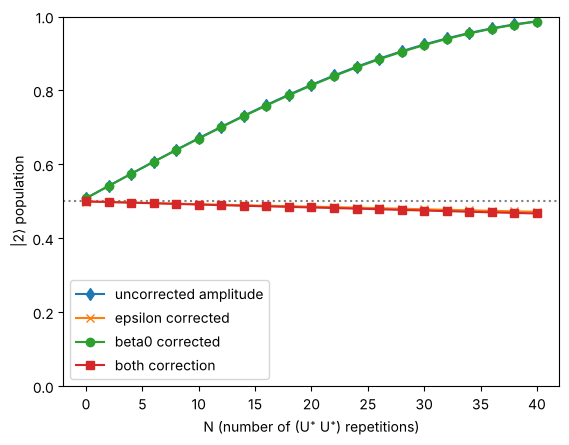

In [9]:
fig, ax = plt.subplots()
ax.axhline(0.5, color='gray', linestyle=':')
ax.plot(aae_Nvalues, aae_uncorrected, '-d', label='uncorrected amplitude')
ax.plot(aae_Nvalues, aae_epsilon_corrected,   '-x', label='epsilon corrected')
ax.plot(aae_Nvalues, aae_beta0_corrected, '-o', label='beta0 corrected')
ax.plot(aae_Nvalues, aae_corrected,  '-s', label='both correction')
ax.set_ylim(0, 1.0)
ax.set_xlabel('N (number of (U⁺ U⁺) repetitions)')
ax.set_ylabel('|2⟩ population')
ax.legend()
plt.show()

In [10]:
# Compare with the cached simulation that notebook 09 plots (same simulation; rerun with the cell
# below only if you want to regenerate the file).
stored = np.load('./data/simulated/aae_21pts_0_40_0.2390_0.2363.npz')
print('max |difference| bare:', np.abs(stored['arr_1'] - aae_uncorrected).max(),
      ' corrected:', np.abs(stored['arr_2'] - aae_corrected).max())
# np.savez('./data/simulated/aae_21pts_0_40_0.2390_0.2363.npz', aae_Nvalues, aae_uncorrected, aae_corrected)


max |difference| bare: 5.390301949237397e-08  corrected: 6.24593708975496e-08
